# Import Packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using HypothesisTests
using LaTeXStrings
using Trapz



In [2]:
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

redSamples (generic function with 2 methods)

# Load Posteriors

In [3]:
poster1 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.csv", DataFrame));

posterR2 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_Ran1c_Try1c.csv", DataFrame));
posterI2 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_ID1_Try1.csv", DataFrame));
posterO2 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_OED1_Try1.csv", DataFrame));

posterR3 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_Ran2d_Try1.csv", DataFrame));
posterI3 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_ID2b_Try1.csv", DataFrame));
posterO3 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_OED2_Try1.csv", DataFrame));

posterR3b = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_Ran2g_Try1.csv", DataFrame));

posterO3b = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_OED2b_Try1.csv", DataFrame));

In [4]:
poster1Cut = hcat(poster1[:,1], poster1[:,3:12], poster1[:,14:end]);

posterR2Cut = hcat(posterR2[:,1], posterR2[:,3:12], posterR2[:,14:end]);
posterI2Cut = hcat(posterI2[:,1], posterI2[:,3:12], posterI2[:,14:end]);
posterO2Cut = hcat(posterO2[:,1], posterO2[:,3:12], posterO2[:,14:end]);

posterR3Cut = hcat(posterR3[:,1], posterR3[:,3:12], posterR3[:,14:end]);
posterI3Cut = hcat(posterI3[:,1], posterI3[:,3:12], posterI3[:,14:end]);
posterO3Cut = hcat(posterO3[:,1], posterO3[:,3:12], posterO3[:,14:end]);

posterR3bCut = hcat(posterR3b[:,1], posterR3b[:,3:12], posterR3b[:,14:end]);
posterO3bCut = hcat(posterO3b[:,1], posterO3b[:,3:12], posterO3b[:,14:end]);


# Plot Posteriors Against True Theta

In [5]:
namess = [L"T_1^L", L"k_{in}", L"k_{pl}", L"k_{bn}", L"k_{un}", L"k_{bp}", L"k_{up}", L"k_{un}^E", L"k_{bn}^E", L"k_i", L"k_r", L"NADH_0", L"NAD_0", L"LDH_0"];

#### Iter 1

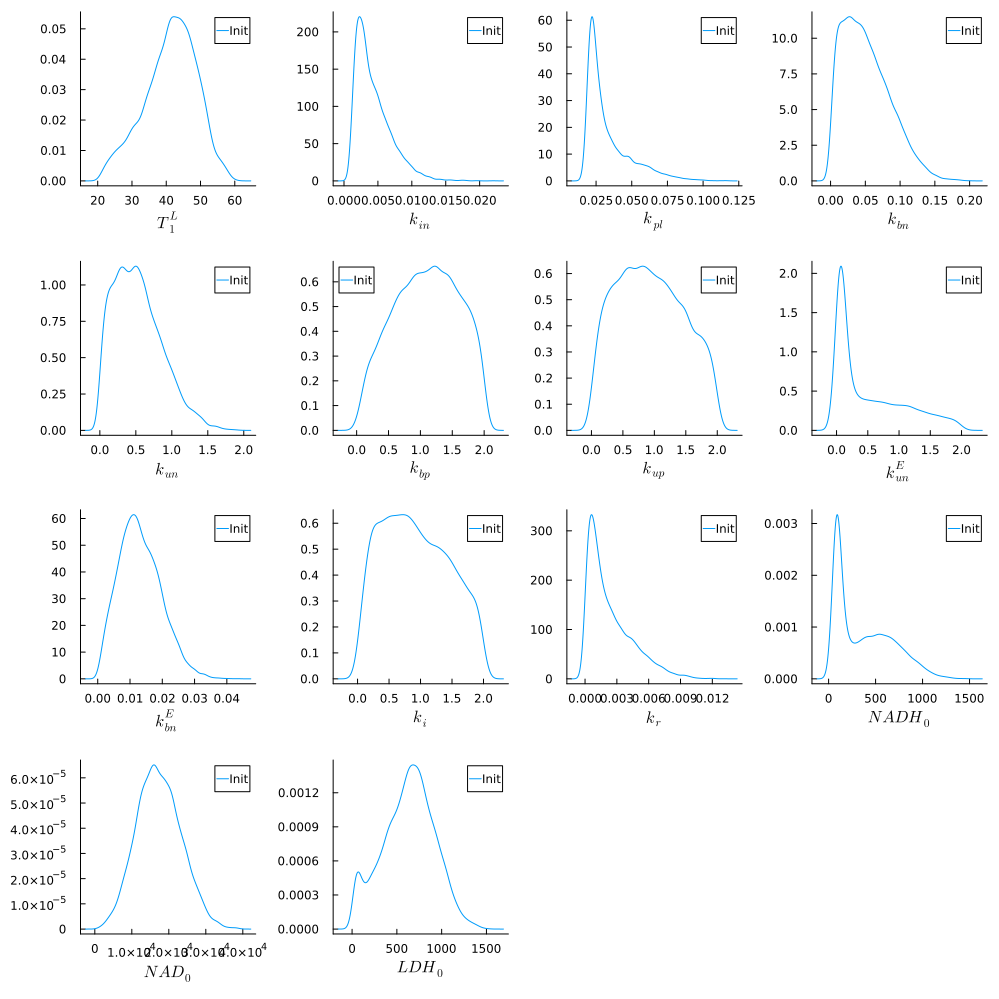

In [6]:
pls = Array{Any}(undef, length(namess));

i = 1
for i in 1:14
    pp1 = plot(kde(poster1Cut[:,i]), label = "Init", grid = false, xlabel = namess[i])

    pls[i] = pp1
end

plot(pls[1],pls[2],pls[3],pls[4], pls[5],pls[6],pls[7],pls[8],pls[9],pls[10],pls[11],pls[12],pls[13],pls[14], size = (1000,1000))

In [ ]:
# pc = corrplot(posterR1Cut[:,10:13], label = namess)
# fp1 = plot(pc, size=(800,600), xtickfont=font(4), ytickfont=font(4), guidefont=font(10))

In [ ]:
# pc = corrplot(posterO1Cut, label = namess)
# fp1 = plot(pc, size=(800,600), xtickfont=font(4), ytickfont=font(4), guidefont=font(10))

#### Iter 2

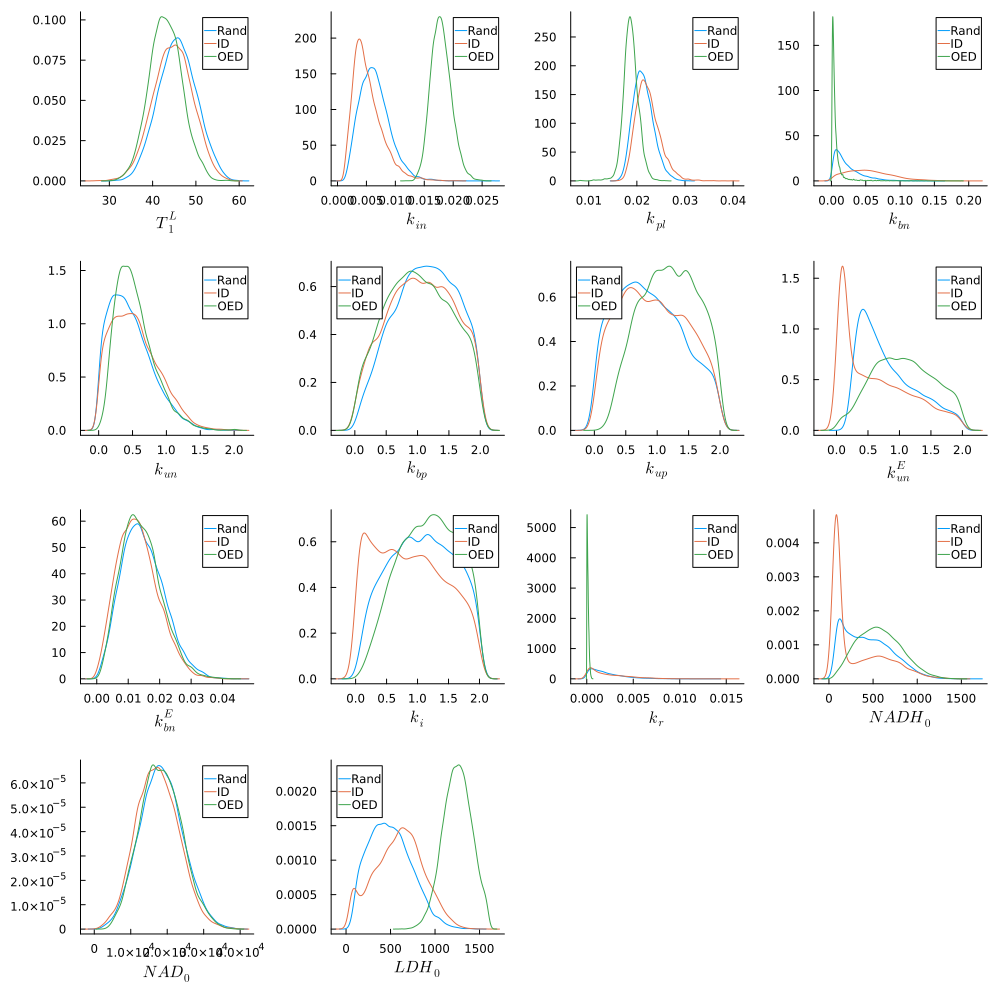

In [9]:
pls = Array{Any}(undef, length(namess));

i = 1
for i in 1:14
    pp1 = plot(kde(posterR2Cut[:,i]), label = "Rand", grid = false, xlabel = namess[i])
    plot!(kde(posterI2Cut[:,i]), label = "ID")
    plot!(kde(posterO2Cut[:,i]), label = "OED")

    pls[i] = pp1
end

plot(pls[1],pls[2],pls[3],pls[4], pls[5],pls[6],pls[7],pls[8],pls[9],pls[10],pls[11],pls[12],pls[13],pls[14], size = (1000,1000))

#### Iter 3

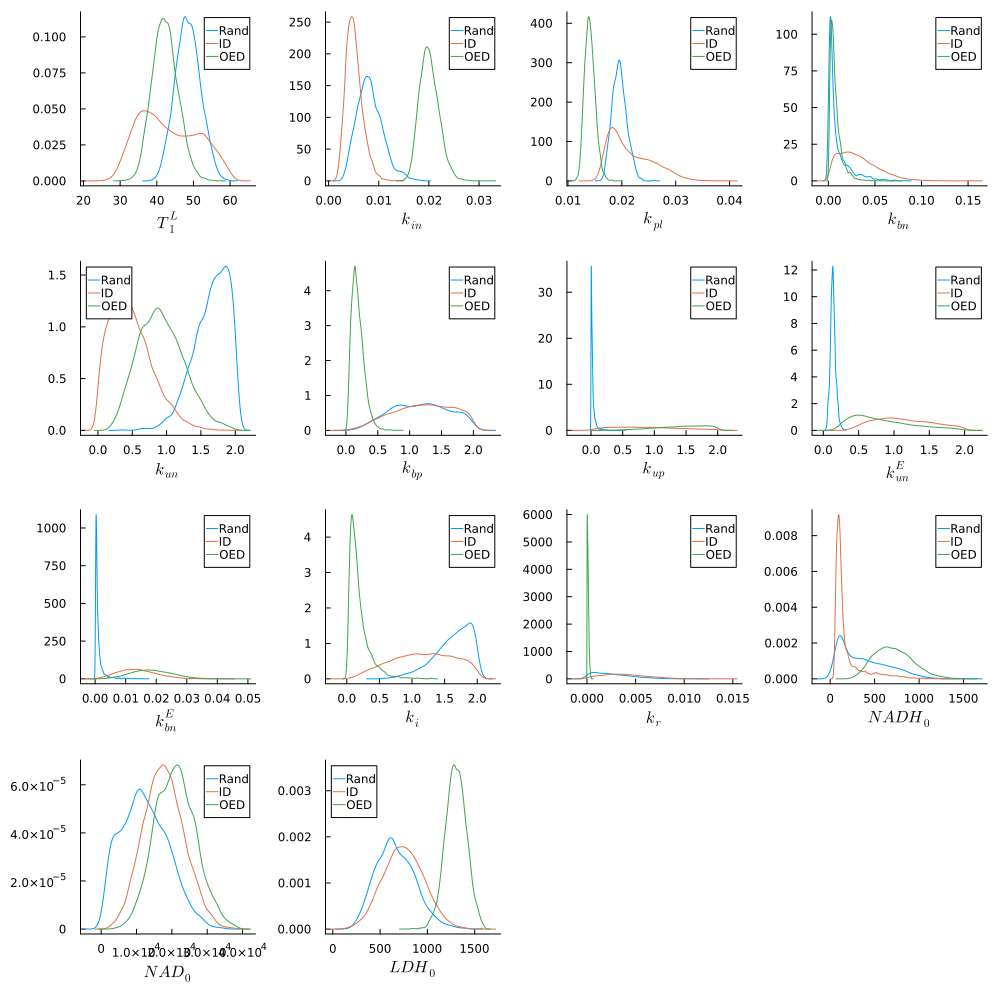

In [8]:
pls = Array{Any}(undef, length(namess));

i = 1
for i in 1:14
    pp1 = plot(kde(posterR3Cut[:,i]), label = "Rand", grid = false, xlabel = namess[i])
    plot!(kde(posterI3Cut[:,i]), label = "ID")
    plot!(kde(posterO3Cut[:,i]), label = "OED")

    pls[i] = pp1
end

plot(pls[1],pls[2],pls[3],pls[4], pls[5],pls[6],pls[7],pls[8],pls[9],pls[10],pls[11],pls[12],pls[13],pls[14], size = (1000,1000))

# Posterior Covariance Determinant

The lower the metric, the better

In [7]:
# Posteriors
CovsR = [log(det(cov(poster1Cut))), log(det(cov(posterR2Cut))), log(det(cov(posterR3Cut)))];
CovsRb = [log(det(cov(poster1Cut))), log(det(cov(posterR2Cut))), log(det(cov(posterR3bCut)))];

CovsI = [log(det(cov(poster1Cut))), log(det(cov(posterI2Cut))), log(det(cov(posterI3Cut)))];
CovsO = [log(det(cov(poster1Cut))), log(det(cov(posterO2Cut))), log(det(cov(posterO3Cut)))];

CovsOb = [log(det(cov(poster1Cut))), log(det(cov(posterO2Cut))), log(det(cov(posterO3bCut)))];

In [8]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\CovMods.jld", "CovsR", CovsR, "CovsRb", CovsRb, "CovsI", CovsI, "CovsO", CovsO, "CovsOb", CovsOb)

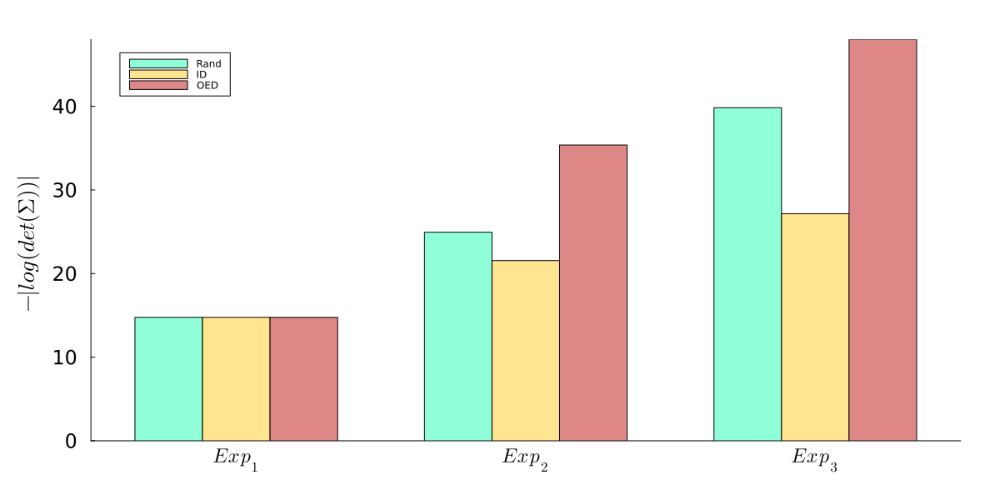

In [12]:
groupedbar(abs.([CovsR CovsI CovsO]) , bar_position = :dodge, bar_width=0.7, label = ["Rand" "ID" "OED"], colour = ["#90ffd9ff" "#ffe590ff" "#de8787ff"], xticks = (1:3, [L"Exp_1", L"Exp_2", L"Exp_3"]), 
        ylabel = L"-|log(det(\Sigma))|", margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
        size = (1200,600), grid = false)

# Entropy Difference

The higher the metric, the better

In [13]:
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\EntropyEstimationPosterior.jl")
using ScikitLearn.GridSearch
using ScikitLearnBase
using GaussianMixtures

In [14]:
mes = [40.92, 0.0055, 0.0275, 0.045, 0.45, 0.95, 0.95, 0.95, 0.0085, 0.95, 0.0029, 650, 16000, 550];
sts = [10, 0.0055, 0.0275, 0.045, 0.45, 0.95, 0.95, 0.95, 0.0085, 0.95, 0.0029, 260, 6400, 275];

HPrior = entropy(MvNormal(mes, Diagonal(ones(14)).*sts));
HPrior

19.231143119623027

Sometimes optimisations fail. Just re-run the cell in that case. 

Init

In [28]:
grid_searchM1FR = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), poster1Cut)

grid_searchM1FbR = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR.best_estimator_.n*4:grid_searchM1FR.best_estimator_.n*4)), verbose=0), poster1Cut)

K-means converged with 8 iterations (objv = 2.4542121305798668e10)
K-means converged with 8 iterations (objv = 2.5532490763557648e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 8 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 8 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 8 iterations (objv = 2.4981065102683964e10)
K-means converged with 21 iterations (objv = 1.99239960868526e10)
K-means converged with 30 iterations (objv = 2.0158149035546967e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 8 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 3000 data points using 21 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 3000 data points using 30 iterations
│ 66.7 data points per par

K-means converged with 33 iterations (objv = 1.9287677014988495e10)
K-means converged with 38 iterations (objv = 1.6681628777714817e10)


...

K-means terminated without convergence after 50 iterations (objv = 2.6026155873287215e9)


┌ Info: Initializing GMM, 16 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 50 iterations
│ 22.2 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 32 iterations (objv = 3.8358813956843085e9)


┌ Info: Initializing GMM, 16 Gaussians diag covariance 14 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 8000 data points using 32 iterations
│ 33.3 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 -0.8228279901207077
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [32]:
gridsInit = [grid_searchM1FbR];

Random

In [17]:
grid_searchM1FR2 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:10)), verbose=0), posterR2Cut)

grid_searchM1FbR2 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR2.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR2.best_estimator_.n*4:grid_searchM1FR2.best_estimator_.n*4)), verbose=0), posterR2Cut)

zim = sum(grid_searchM1FbR2.best_estimator_.w .== 0)
if zim != 0
        grid_searchM1FbR2 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR2.best_estimator_.n*3, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR2.best_estimator_.n*3:grid_searchM1FR2.best_estimator_.n*3)), verbose=0), posterR2Cut)
end

K-means converged with 13 iterations (objv = 2.2687301584499916e10)
K-means converged with 7 iterations (objv = 2.1866675015881897e10)

┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 13 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79



K-means converged with 10 iterations (objv = 2.389259837719803e10)
K-means converged with 17 iterations (objv = 1.6973479710465656e10)


┌ Info: K-means with 2000 data points using 7 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 10 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 30 iterations (objv = 1.777514986724032e10)
K-means converged with 18 iterations (objv = 1.7430224572384197e10)


...

┌ Info: Initializing GMM, 36 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5333 data points using 44 iterations
│ 9.9 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means terminated without convergence after 50 iterations (objv = 9.586227352440492e8)


┌ Info: Initializing GMM, 36 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 50 iterations
│ 9.9 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Warning: Too low occupancy count 0.0 for Gausian 8
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: Too low occupancy count 0.0 for Gausian 23
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 28 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 8
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: Too low occupancy count 0.0 for Gausian 23
└

K-means terminated without convergence after 50 iterations (objv = 1.485338217134951e9)


┌ Info: K-means with 8000 data points using 50 iterations
│ 14.8 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


In [29]:
grid_searchM1FR3 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:10)), verbose=0), posterR3Cut)

grid_searchM1FbR3 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR3.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR3.best_estimator_.n*4:grid_searchM1FR3.best_estimator_.n*4)), verbose=0), posterR3Cut)

zim = sum(grid_searchM1FbR3.best_estimator_.w .== 0)
if zim != 0
        grid_searchM1FbR3 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR3.best_estimator_.n*3, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR3.best_estimator_.n*3:grid_searchM1FR3.best_estimator_.n*3)), verbose=0), posterR3Cut)
end

K-means converged with 8 iterations (objv = 2.221173293539573e10)
K-means converged with 7 iterations (objv = 2.242896183190975e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 8 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 7 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 11 iterations (objv = 2.1405194712863914e10)
K-means converged with 39 iterations (objv = 1.7482559531501816e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 11 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 3000 data points using 39 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 30 iterations (objv = 1.6601466479638115e10)
K-means converged with 20 iterations (objv = 1.7637831867928368e10)


...

┌ Info: K-means with 5333 data points using 45 iterations
│ 9.9 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 46 iterations (objv = 5.898593901574726e8)


┌ Info: Initializing GMM, 36 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 45 iterations (objv = 8.606952604987634e8)


┌ Info: K-means with 5334 data points using 46 iterations
│ 9.9 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 36 Gaussians diag covariance 14 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 8000 data points using 45 iterations
│ 14.8 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


In [19]:
grid_searchM1FR3b = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:10)), verbose=0), posterR3bCut)

grid_searchM1FbR3b = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR3b.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR3b.best_estimator_.n*4:grid_searchM1FR3b.best_estimator_.n*4)), verbose=0), posterR3bCut)

zim = sum(grid_searchM1FbR3b.best_estimator_.w .== 0)
if zim != 0
        grid_searchM1FbR3b = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR3b.best_estimator_.n*3, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR3b.best_estimator_.n*3:grid_searchM1FR3b.best_estimator_.n*3)), verbose=0), posterR3bCut)
end

K-means converged with 14 iterations (objv = 2.9980936657286682e10)
K-means converged with 10 iterations (objv = 2.9627236580709953e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 14 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 16 iterations (objv = 2.9046829933470146e10)
K-means converged with 11 iterations (objv = 2.099685857675801e10)


┌ Info: K-means with 2000 data points using 10 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 16 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 28 iterations (objv = 2.169635704286294e10)
K-means converged with 16 iterations (objv = 2.1477079529380554e10)


...

K-means terminated without convergence after 50 iterations (objv = 1.1081677291045933e9)


┌ Info: K-means with 5334 data points using 50 iterations
│ 11.9 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Warning: Too low occupancy count 0.0 for Gausian 12
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 12
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 12
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packag

K-means terminated without convergence after 50 iterations (objv = 1.6411778783526168e9)


┌ Info: K-means with 8000 data points using 50 iterations
│ 17.8 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 0.4150303524754753
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [33]:
gridsR = [grid_searchM1FbR, grid_searchM1FbR2, grid_searchM1FbR3];
gridsRb = [grid_searchM1FbR, grid_searchM1FbR2, grid_searchM1FbR3b];

Intuition Driven 

In [38]:
grid_searchM1FI2 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:10)), verbose=0), posterI2Cut)

grid_searchM1FbI2 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FI2.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FI2.best_estimator_.n*4:grid_searchM1FI2.best_estimator_.n*4)), verbose=0), posterI2Cut)

# zim = sum(grid_searchM1FbI2.best_estimator_.w .== 0)
# if zim != 0
#         grid_searchM1FbI2 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FI2.best_estimator_.n*3-zim, kind=:full), 
#         Dict(:n_components=>collect(grid_searchM1FI2.best_estimator_.n*3-zim:grid_searchM1FI2.best_estimator_.n*3-zim)), verbose=0), posterI2Cut)
# end

K-means converged with 11 iterations (objv = 2.4449170232205795e10)
K-means converged with 17 iterations (objv = 2.474945545584358e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 11 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 20 iterations (objv = 2.281731772026495e10)
K-means converged with 22 iterations (objv = 1.9815710017255478e10)


┌ Info: K-means with 2000 data points using 17 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 20 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 3000 data points using 22 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 27 iterations (objv = 1.9640357144157646e10)
K-means converged with 19 iterations (objv = 1.9230789808864853e10)


...

K-means terminated without convergence after 50 iterations (objv = 1.3554912115495296e9)
K-means converged with 29 iterations (objv = 1.381290134139957e9)


┌ Info: K-means with 5333 data points using 50 iterations
│ 12.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 28 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 29 iterations
│ 12.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Warning: Too low occupancy count 13.9 for Gausian 5
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: Too low occupancy count 11.6 for Gausian 5
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Info: Initializing GMM, 28 Gaussians diag covariance 14 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianM

K-means converged with 42 iterations (objv = 2.1029291376966562e9)


┌ Info: K-means with 8000 data points using 42 iterations
│ 19.0 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 -0.43157201301296955
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [22]:
grid_searchM1FI3 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:10)), verbose=0), posterI3Cut)

grid_searchM1FbI3 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FI3.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FI3.best_estimator_.n*4:grid_searchM1FI3.best_estimator_.n*4)), verbose=0), posterI3Cut)

# zim = sum(grid_searchM1FbI3.best_estimator_.w .== 0)
# if zim != 0
#         grid_searchM1FbI3 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FI3.best_estimator_.n*3-zim, kind=:full), 
#         Dict(:n_components=>collect(grid_searchM1FI3.best_estimator_.n*3-zim:grid_searchM1FI3.best_estimator_.n*3-zim)), verbose=0), posterI3Cut)
# end

K-means converged with 8 iterations (objv = 2.3581335071158707e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 7 iterations (objv = 2.369890274596237e10)
K-means converged with 20 iterations (objv = 2.5327803107450047e10)


┌ Info: K-means with 2000 data points using 8 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 7 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 20 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 24 iterations (objv = 1.7631808703257866e10)
K-means converged with 14 iterations (objv = 1.75166252480655e10)


...

K-means terminated without convergence after 50 iterations (objv = 1.1325464774402616e9)


┌ Info: K-means with 5333 data points using 50 iterations
│ 14.8 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 24 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means terminated without convergence after 50 iterations (objv = 1.877152310813682e9)


┌ Info: K-means with 5334 data points using 50 iterations
│ 14.8 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 24 Gaussians diag covariance 14 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 8000 data points using 50 iterations
│ 22.2 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 -0.3025766112083916
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [39]:
gridsI = [grid_searchM1FbR, grid_searchM1FbI2, grid_searchM1FbI3];

OED

In [24]:
grid_searchM1FO2 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:10)), verbose=0), posterO2Cut)

grid_searchM1FbO2 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FO2.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FO2.best_estimator_.n*4:grid_searchM1FO2.best_estimator_.n*4)), verbose=0), posterO2Cut)

K-means converged with 11 iterations (objv = 2.1540216753479126e10)
K-means converged with 8 iterations (objv = 2.1178787340192707e10)
K-means converged with 7 iterations (objv = 2.418182152361808e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 11 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 8 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 7 iterations
│ 66.7 data points per para

K-means converged with 33 iterations (objv = 1.6847551625225143e10)
K-means converged with 29 iterations (objv = 1.6999727879842352e10)


┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 3000 data points using 33 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 19 iterations (objv = 1.844059498405106e10)
K-means converged with 36 iterations (objv = 1.3700379822462996e10)


...

K-means converged with 36 iterations (objv = 8.007122435384275e8)


┌ Info: Initializing GMM, 32 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means terminated without convergence after 50 iterations (objv = 1.2192071608544295e9)


┌ Info: K-means with 5334 data points using 36 iterations
│ 11.1 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 32 Gaussians diag covariance 14 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 8000 data points using 50 iterations
│ 16.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 -0.023179090519436455
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [25]:
grid_searchM1FO3 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:10)), verbose=0), posterO3Cut)

grid_searchM1FbO3 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FO3.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FO3.best_estimator_.n*4:grid_searchM1FO3.best_estimator_.n*4)), verbose=0), posterO3Cut)

K-means converged with 11 iterations (objv = 2.2208377892396736e10)
K-means converged with 15 iterations (objv = 2.4297126060447617e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 11 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 9 iterations (objv = 2.112818643735792e10)
K-means converged with 18 iterations (objv = 1.738652222703101e10)


┌ Info: K-means with 2000 data points using 15 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 9 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 20 iterations (objv = 1.7628491809510765e10)
K-means converged with 29 iterations (objv = 1.8265742142355484e10)


...

K-means converged with 40 iterations (objv = 5.548714018708673e8)


┌ Warning: Too low occupancy count 0.0 for Gausian 9
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Info: Initializing GMM, 40 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 40 iterations
│ 8.9 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Warning: Too low occupancy count 0.0 for Gausian 9
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 9
└ @ Gaussi

K-means terminated without convergence after 50 iterations (objv = 8.18510108126915e8)


┌ Info: K-means with 8000 data points using 50 iterations
│ 13.3 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Warning: Too low occupancy count 0.0 for Gausian 3
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 3
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 3
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\

GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 0.38716043418388696
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [27]:
grid_searchM1FO3b = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:10)), verbose=0), posterO3bCut)

grid_searchM1FbO3b = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FO3b.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FO3b.best_estimator_.n*4:grid_searchM1FO3b.best_estimator_.n*4)), verbose=0), posterO3bCut)

K-means converged with 12 iterations (objv = 2.083520845629592e10)
K-means converged with 12 iterations (objv = 2.1771023669175446e10)
K-means converged with 14 iterations (objv = 2.20164435008546e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 12 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 12 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 14 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 14 iterations
│ 66.7 data points per pa

K-means converged with 24 iterations (objv = 1.7351439609328705e10)
K-means converged with 12 iterations (objv = 1.7364433195289314e10)


┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 3000 data points using 24 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 14 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 3000 data points using 12 iterations
│ 66.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 18 iterations (objv = 1.7276188343716232e10)
K-means converged with 30 iterations (objv = 1.4023376724942192e10)


...

K-means converged with 41 iterations (objv = 8.159736942918072e8)


┌ Info: K-means with 5334 data points using 41 iterations
│ 11.1 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Warning: Too low occupancy count 0.0 for Gausian 24
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 24
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 24
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packag

K-means terminated without convergence after 50 iterations (objv = 1.1885191375175855e9)


┌ Info: K-means with 8000 data points using 50 iterations
│ 16.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Warning: Too low occupancy count 0.0 for Gausian 14
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 14
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 14
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 14 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packag

GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 0.18327307071663088
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [31]:
gridsO = [grid_searchM1FbR, grid_searchM1FbO2, grid_searchM1FbO3];
gridsOb = [grid_searchM1FbR, grid_searchM1FbO2, grid_searchM1FbO3b];

In [40]:
# First dimension number of experiments, second dimension type of experiments.
comps = Array{Any,2}(undef,3, 5);
weis = Array{Any,2}(undef, 3, 5);
meaas = Array{Any,2}(undef,3, 5);
covas = Array{Any,2}(undef,3, 5);

for i in 1:3 #number of experiments
    # Get and store best results
    comps[i,1] = length(gridsR[i].best_estimator_.w); # Number of components
    weis[i,1] = gridsR[i].best_estimator_.w; # Weights for each component
    meaas[i,1] = gridsR[i].best_estimator_.μ; # Means for each component
    covas[i,1] = [inv(Matrix(gridsR[i].best_estimator_.Σ[j]))*inv(Matrix(gridsR[i].best_estimator_.Σ[j])') 
        for j in 1:length(gridsR[i].best_estimator_.Σ)]; # Covariance Matrix for each component

    comps[i,2] = length(gridsRb[i].best_estimator_.w); # Number of components
    weis[i,2] = gridsRb[i].best_estimator_.w; # Weights for each component
    meaas[i,2] = gridsRb[i].best_estimator_.μ; # Means for each component
    covas[i,2] = [inv(Matrix(gridsRb[i].best_estimator_.Σ[j]))*inv(Matrix(gridsRb[i].best_estimator_.Σ[j])') 
        for j in 1:length(gridsRb[i].best_estimator_.Σ)]; # Covariance Matrix for each component

    comps[i,3] = length(gridsI[i].best_estimator_.w); # Number of components
    weis[i,3] = gridsI[i].best_estimator_.w; # Weights for each component
    meaas[i,3] = gridsI[i].best_estimator_.μ; # Means for each component
    covas[i,3] = [inv(Matrix(gridsI[i].best_estimator_.Σ[j]))*inv(Matrix(gridsI[i].best_estimator_.Σ[j])') 
        for j in 1:length(gridsI[i].best_estimator_.Σ)];

    comps[i,4] = length(gridsO[i].best_estimator_.w); # Number of components
    weis[i,4] = gridsO[i].best_estimator_.w; # Weights for each component
    meaas[i,4] = gridsO[i].best_estimator_.μ; # Means for each component
    covas[i,4] = [inv(Matrix(gridsO[i].best_estimator_.Σ[j]))*inv(Matrix(gridsO[i].best_estimator_.Σ[j])') 
        for j in 1:length(gridsO[i].best_estimator_.Σ)];

    comps[i,5] = length(gridsOb[i].best_estimator_.w); # Number of components
    weis[i,5] = gridsOb[i].best_estimator_.w; # Weights for each component
    meaas[i,5] = gridsOb[i].best_estimator_.μ; # Means for each component
    covas[i,5] = [inv(Matrix(gridsOb[i].best_estimator_.Σ[j]))*inv(Matrix(gridsOb[i].best_estimator_.Σ[j])') 
        for j in 1:length(gridsOb[i].best_estimator_.Σ)];
end


In [41]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\GMMPosters.jld", "comps", comps, "weis", weis, "meaas", meaas, "covas", covas)

In [30]:
comps = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\GMMPosters.jld")["comps"];
weis = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\GMMPosters.jld")["weis"];
meaas = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\GMMPosters.jld")["meaas"];
covas = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\GMMPosters.jld")["covas"];

In [42]:
H_U_Post = Array{Any,2}(undef,3,5);
H_L_Post = Array{Any,2}(undef,3,5);
H_Post = Array{Any,2}(undef,3,5);

for j in 1:3# number of experiments
    [H_U_Post[j,i] = H_Upper(weis[j,i], covas[j,i]) for i in 1:5];
    [H_L_Post[j,i] = H_Lower(weis[j,i], covas[j,i], meaas[j,i]) for i in 1:5];
    [H_Post[j,i] = H_est(comps[j,i], weis[j,i], meaas[j,i], covas[j,i]) for i in 1:5];
end

              Iteration 1 of 16
              Iteration 2 of 16
              Iteration 3 of 16
              Iteration 4 of 16
              Iteration 5 of 16
              Iteration 6 of 16
              Iteration 7 of 16
              Iteration 8 of 16
              Iteration 9 of 16
              Iteration 10 of 16
              Iteration 11 of 16
              Iteration 12 of 16
              Iteration 13 of 16
              Iteration 14 of 16
              Iteration 15 of 16
              Iteration 16 of 16
              Iteration 1 of 16
              Iteration 2 of 16
              Iteration 3 of 16
              Iteration 4 of 16
              Iteration 5 of 16
              Iteration 6 of 16
              Iteration 7 of 16
              Iteration 8 of 16
              Iteration 9 of 16
              Iteration 10 of 16
              Iteration 11 of 16
              Iteration 12 of 16
              Iteration 13 of 16
              Iteration 14 of 16
              Iteration 15 o

In [43]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\EntroPosters.jld", "H_U_Post", H_U_Post, "H_L_Post", H_L_Post, "H_Post", H_Post, "HPrior", HPrior)

In [44]:
H_U_Post = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\EntroPosters.jld")["H_U_Post"];
H_L_Post = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\EntroPosters.jld")["H_L_Post"];
H_Post = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\EntroPosters.jld")["H_Post"];

In [45]:
display(string("              |     H Lower Bound      |            H            |      H Upper Bound      |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 1   |      ",round(H_L_Post[1,1], digits = 8),"      |       ",round(H_Post[1,1], digits = 9),"        |       ",round(H_U_Post[1,1], digits = 9),"       |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 2   |      ",round(H_L_Post[2,1], digits = 8),"      |       ",round(H_Post[2,1], digits = 6),"        |       ",round(H_U_Post[2,1], digits = 8),"        |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 3   |      ",round(H_L_Post[3,1], digits = 8),"      |       ",round(H_Post[3,1], digits = 6),"         |       ",round(H_U_Post[3,1], digits = 8),"       |"))
display("--------------------------------------------------------------------------------------------")


"              |     H Lower Bound      |            H            |      H Upper Bound      |"

"--------------------------------------------------------------------------------------------"

"|    Rand 1   |      -1.86259563      |       0.251702774        |       11.592931849       |"

"--------------------------------------------------------------------------------------------"

"|    Rand 2   |      -8.53465454      |       -6.498291        |       4.9264062        |"

"--------------------------------------------------------------------------------------------"

"|    Rand 3   |      -16.28485683      |       -14.14164         |       -2.75649903       |"

"--------------------------------------------------------------------------------------------"

In [47]:
display(string("              |     H Lower Bound      |            H            |      H Upper Bound      |"))
display("--------------------------------------------------------------------------------------------")
display(string("|   Randb 1   |      ",round(H_L_Post[1,2], digits = 8),"      |       ",round(H_Post[1,2], digits = 9),"        |       ",round(H_U_Post[1,2], digits = 9),"       |"))
display("--------------------------------------------------------------------------------------------")
display(string("|   Randb 2   |      ",round(H_L_Post[2,2], digits = 8),"      |       ",round(H_Post[2,2], digits = 6),"        |       ",round(H_U_Post[2,2], digits = 8),"        |"))
display("--------------------------------------------------------------------------------------------")
display(string("|   Randb 3   |      ",round(H_L_Post[3,2], digits = 8),"      |       ",round(H_Post[3,2], digits = 6),"         |       ",round(H_U_Post[3,2], digits = 8),"       |"))
display("--------------------------------------------------------------------------------------------")


"              |     H Lower Bound      |            H            |      H Upper Bound      |"

"--------------------------------------------------------------------------------------------"

"|   Randb 1   |      -3.3391775      |       -1.223088655        |       10.05081303       |"

"--------------------------------------------------------------------------------------------"

"|   Randb 2   |      -8.50907626      |       -6.358269        |       4.97673757        |"

"--------------------------------------------------------------------------------------------"

"|   Randb 3   |      -19.51296377      |       -17.250181         |       NaN       |"

"--------------------------------------------------------------------------------------------"

In [48]:
display(string("              |     H Lower Bound      |            H            |      H Upper Bound      |"))
display("--------------------------------------------------------------------------------------------")
display(string("|     ID 1    |      ",round(H_L_Post[1,3], digits = 8),"      |       ",round(H_Post[1,3], digits = 9),"        |       ",round(H_U_Post[1,3], digits = 9),"       |"))
display("--------------------------------------------------------------------------------------------")
display(string("|     ID 2    |      ",round(H_L_Post[2,3], digits = 8),"      |       ",round(H_Post[2,3], digits = 6),"        |       ",round(H_U_Post[2,3], digits = 8),"        |"))
display("--------------------------------------------------------------------------------------------")
display(string("|     ID 3    |      ",round(H_L_Post[3,3], digits = 8),"      |       ",round(H_Post[3,3], digits = 6),"         |       ",round(H_U_Post[3,3], digits = 8),"       |"))
display("--------------------------------------------------------------------------------------------")


"              |     H Lower Bound      |            H            |      H Upper Bound      |"

"--------------------------------------------------------------------------------------------"

"|     ID 1    |      -3.3391775      |       -1.223088655        |       10.05081303       |"

"--------------------------------------------------------------------------------------------"

"|     ID 2    |      -7.76321998      |       -5.977641        |       5.66634909        |"

"--------------------------------------------------------------------------------------------"

"|     ID 3    |      -9.60559704      |       -7.437961         |       3.81747902       |"

"--------------------------------------------------------------------------------------------"

In [49]:
display(string("              |     H Lower Bound      |            H            |      H Upper Bound      |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    OED 1    |      ",round(H_L_Post[1,4], digits = 8),"      |       ",round(H_Post[1,4], digits = 9),"        |       ",round(H_U_Post[1,4], digits = 9),"       |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    OED 2    |      ",round(H_L_Post[2,4], digits = 8),"      |       ",round(H_Post[2,4], digits = 6),"        |       ",round(H_U_Post[2,4], digits = 8),"        |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    OED 3    |      ",round(H_L_Post[3,4], digits = 8),"      |       ",round(H_Post[3,4], digits = 6),"         |       ",round(H_U_Post[3,4], digits = 8),"       |"))
display("--------------------------------------------------------------------------------------------")


"              |     H Lower Bound      |            H            |      H Upper Bound      |"

"--------------------------------------------------------------------------------------------"

"|    OED 1    |      -3.3391775      |       -1.223088655        |       10.05081303       |"

"--------------------------------------------------------------------------------------------"

"|    OED 2    |      -13.83572278      |       -11.640195        |       NaN        |"

"--------------------------------------------------------------------------------------------"

"|    OED 3    |      -19.6255747      |       -17.334105         |       -6.17598737       |"

"--------------------------------------------------------------------------------------------"

In [46]:
display(string("              |     H Lower Bound      |            H            |      H Upper Bound      |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    OEDb 1    |      ",round(H_L_Post[1,5], digits = 8),"      |       ",round(H_Post[1,5], digits = 9),"        |       ",round(H_U_Post[1,5], digits = 9),"       |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    OEDb 2    |      ",round(H_L_Post[2,5], digits = 8),"      |       ",round(H_Post[2,5], digits = 6),"        |       ",round(H_U_Post[2,5], digits = 8),"        |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    OEDb 3    |      ",round(H_L_Post[3,5], digits = 8),"      |       ",round(H_Post[3,5], digits = 6),"         |       ",round(H_U_Post[3,5], digits = 8),"       |"))
display("--------------------------------------------------------------------------------------------")


"              |     H Lower Bound      |            H            |      H Upper Bound      |"

"--------------------------------------------------------------------------------------------"

"|    OEDb 1    |      -1.86259563      |       0.251702774        |       11.592931849       |"

"--------------------------------------------------------------------------------------------"

"|    OEDb 2    |      -13.79542807      |       -11.487156        |       -0.2675944        |"

"--------------------------------------------------------------------------------------------"

"|    OEDb 3    |      -16.58282502      |       -14.549943         |       NaN       |"

"--------------------------------------------------------------------------------------------"

In [51]:
H_gain = Array{Any,2}(undef,3,5);
[H_gain[j,i] = HPrior-H_Post[j,i] for i in 1:5 for j in 1:3];


In [52]:
H_gain

3×5 Matrix{Any}:
 18.9794  18.9794  18.9794  18.9794  18.9794
 25.7294  25.7294  24.645   30.7183  30.7183
 33.3728  36.9925  26.7497  36.6632  33.7811

In [41]:
display(string("              |    Entropy Gain Rand   |    Entropy Gain IDs    |    Entropy Gain OEDs   |"))
display("------------------------------------------------------------------------------------------")
display(string("|    Mod 1    |      ",round(H_gain[1,1], digits = 9),"      |      ",round(H_gain[1,2], digits = 9),"      |      ",round(H_gain[1,3], digits = 9),"      |"))
display("------------------------------------------------------------------------------------------")
display(string("|    Mod 2    |      ",round(H_gain[2,1], digits = 9),"      |      ",round(H_gain[2,2], digits = 9),"        |      ",round(H_gain[2,3], digits = 9),"        |"))
display("------------------------------------------------------------------------------------------")
display(string("|    Mod 2    |      ",round(H_gain[3,1], digits = 9),"      |      ",round(H_gain[3,2], digits = 9),"        |      ",round(H_gain[3,3], digits = 9),"        |"))
display("------------------------------------------------------------------------------------------")


"              |    Entropy Gain Rand   |    Entropy Gain IDs    |    Entropy Gain OEDs   |"

"------------------------------------------------------------------------------------------"

"|    Mod 1    |      20.519943323      |      20.519943323      |      20.519943323      |"

"------------------------------------------------------------------------------------------"

"|    Mod 2    |      24.322787629      |      25.320986097        |      30.729450458        |"

"------------------------------------------------------------------------------------------"

"|    Mod 2    |      37.929193466      |      26.826320322        |      36.785922459        |"

"------------------------------------------------------------------------------------------"

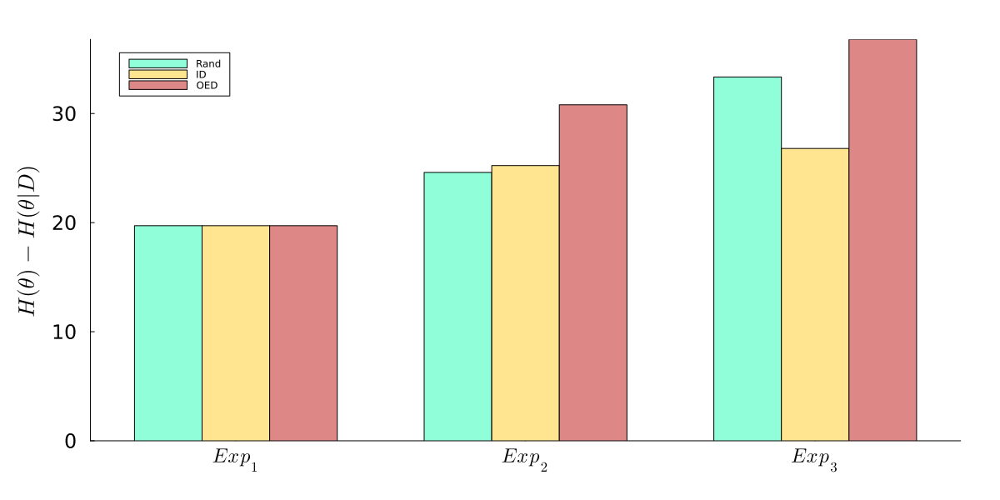

In [50]:
groupedbar(abs.([H_gain[:,1] H_gain[:,2] H_gain[:,3]]) , bar_position = :dodge, bar_width=0.7, label = ["Rand" "ID" "OED"], colour = ["#90ffd9ff" "#ffe590ff" "#de8787ff"], xticks = (1:3, [L"Exp_1", L"Exp_2", L"Exp_3"]), 
        ylabel = L"H(\theta)-H(\theta | D)", margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
        size = (1200,600), grid = false)

# Simulation Multiple Concentrations

In [11]:
avScF = 22.36

22.36

In [12]:
test = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\PostTests\\Rand2CPost.csv", DataFrame))

1457×16 Matrix{Float64}:
 45.4193  51.23  0.00531007  0.0187725  …   309.393   16462.9    530.589
 44.6276  51.23  0.00488229  0.0193322      324.251   17733.8    477.127
 44.9207  51.23  0.0047382   0.0177498      507.09    21009.7    286.057
 44.9691  51.23  0.00706172  0.0189408      469.002   24331.7    209.49
 39.9374  51.23  0.00960695  0.0160861      577.186   15990.2    941.68
 43.9337  51.23  0.00784408  0.0177021  …   343.001   19231.1    785.299
 43.9112  51.23  0.00603164  0.0185763      448.593   19291.4    601.287
 44.9227  51.23  0.00652211  0.0184449       90.0327  16167.4    543.247
 44.9566  51.23  0.0117612   0.019844        78.0735  14528.5    810.493
 41.1356  51.23  0.00504637  0.0174743       96.313   15338.0    486.563
  ⋮                                     ⋱                          ⋮
 47.4908  51.23  0.00657292  0.0203264     1090.77     5878.95   700.914
 46.5689  51.23  0.00879856  0.0202427      302.027   20330.0   1002.44
 49.3193  51.23  0.00628432  0.02

In [13]:
# Initial

PyrCons4 = collect(0.01:1:40);
ObsPyrCons4 = PyrCons4.*(1000*0.12*avScF);

tsC2 = 0:1:399
ts = 0:tsC2[end];
samps = convert.(Int, tsC2);

Random.seed!(65464)
# poster4 = poster1[StatsBase.sample(1:8000, 100, replace = false),:];
poster4 = test[StatsBase.sample(1:1457, 100, replace = false),:];

test

posterSims1 = Array{Any}(undef, length(PyrCons4))
for i in 1:length(PyrCons4)
    tmp = zeros(length(samps),14,100);
    for j in 1:100
        ivss = [PyrCons4[i].*1000, 0, 0, poster4[j,end-2], poster4[j,end-1], poster4[j,end], 0, 0, 0, 0, 0, PyrCons4[i].*1000, 0, PyrCons4[i].*(1000*0.12*avScF)];
        SimOnTime1poster, SimOffTime1poster, SimAll1poster  = PyruvateHP_NMR_SolveAllCp(ts, vcat(poster4[j,1:end-4], avScF, zeros(1)), ivss, samps);
        tmp[:,:,j] = SimOnTime1poster[:,:,1]
    end

    posterSims1[i] = tmp;
end

In [22]:
# Random

PyrCons4 = collect(0.01:1:40);
ObsPyrCons4 = PyrCons4.*(1000*0.12*avScF);

tsC2 = 0:1:399
ts = 0:tsC2[end];
samps = convert.(Int, tsC2);

Random.seed!(65464)
iss = 1000
# poster4 = posterR3[StatsBase.sample(1:8000, 400, replace = false),:];
poster4 = posterR3[StatsBase.sample(1:1981, iss, replace = false),:];


posterSimsR = Array{Any}(undef, length(PyrCons4))
for i in 1:length(PyrCons4)
    tmp = zeros(length(samps),14,iss);
    for j in 1:iss
        ivss = [PyrCons4[i].*1000, 0, 0, poster4[j,end-2], poster4[j,end-1], poster4[j,end], 0, 0, 0, 0, 0, PyrCons4[i].*1000, 0, PyrCons4[i].*(1000*0.12*avScF)];
        SimOnTime1poster, SimOffTime1poster, SimAll1poster  = PyruvateHP_NMR_SolveAllCp(ts, vcat(poster4[j,1:end-4], avScF, zeros(1)), ivss, samps);
        tmp[:,:,j] = SimOnTime1poster[:,:,1]
    end

    posterSimsR[i] = tmp;
end

In [23]:
# Intuition Driven

PyrCons4 = collect(0.01:1:40);
ObsPyrCons4 = PyrCons4.*(1000*0.12*avScF);

tsC2 = 0:1:399
ts = 0:tsC2[end];
samps = convert.(Int, tsC2);

iss = 1000
Random.seed!(65464)
poster5 = posterI3[StatsBase.sample(1:8000, iss, replace = false),:];


posterSimsI = Array{Any}(undef, length(PyrCons4))
for i in 1:length(PyrCons4)
    tmp = zeros(length(samps),14,iss);
    for j in 1:iss
        ivss = [PyrCons4[i].*1000, 0, 0, poster5[j,end-2], poster5[j,end-1], poster5[j,end], 0, 0, 0, 0, 0, PyrCons4[i].*1000, 0, PyrCons4[i].*(1000*0.12*avScF)];
        SimOnTime1poster, SimOffTime1poster, SimAll1poster  = PyruvateHP_NMR_SolveAllCp(ts, vcat(poster5[j,1:end-4], avScF, zeros(1)), ivss, samps);
        tmp[:,:,j] = SimOnTime1poster[:,:,1]
    end

    posterSimsI[i] = tmp;
end

In [24]:
# OED

PyrCons4 = collect(0.01:1:40);
ObsPyrCons4 = PyrCons4.*(1000*0.12*avScF);

tsC2 = 0:1:399
ts = 0:tsC2[end];
samps = convert.(Int, tsC2);

Random.seed!(65464)
iss = 1000

poster6 = posterO3[StatsBase.sample(1:8000, iss, replace = false),:];


posterSimsO = Array{Any}(undef, length(PyrCons4))
for i in 1:length(PyrCons4)
    tmp = zeros(length(samps),14,iss);
    for j in 1:iss
        ivss = [PyrCons4[i].*1000, 0, 0, poster6[j,end-2], poster6[j,end-1], poster6[j,end], 0, 0, 0, 0, 0, PyrCons4[i].*1000, 0, PyrCons4[i].*(1000*0.12*avScF)];
        SimOnTime1poster, SimOffTime1poster, SimAll1poster  = PyruvateHP_NMR_SolveAllCp(ts, vcat(poster6[j,1:end-4], avScF, zeros(1)), ivss, samps);
        tmp[:,:,j] = SimOnTime1poster[:,:,1]
    end

    posterSimsO[i] = tmp;
end

In [48]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\SimulationsPosteriorDiffPyrConc_Rand.jld", "posterSimsR", posterSimsR)
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\SimulationsPosteriorDiffPyrConc_InDr.jld", "posterSimsI", posterSimsI)
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\SimulationsPosteriorDiffPyrConc_bOED.jld", "posterSimsO", posterSimsO)

In [ ]:
posterSimsR = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\SimulationsPosteriorDiffPyrConc_Rand.jld")["posterSimsR"];
posterSimsI = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\SimulationsPosteriorDiffPyrConc_InDr.jld")["posterSimsI"];
posterSimsO = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\SimulationsPosteriorDiffPyrConc_bOED.jld")["posterSimsO"];

In [25]:
# Initial
# sumSims1 = zeros(100, length(ObsPyrCons4));
# [sumSims1[j,i] = trapz(samps, posterSims1[i][:,13,j]) for i in 1:length(ObsPyrCons4) for j in 1:100];

# Random
sumSimsR = zeros(100, length(ObsPyrCons4));
[sumSimsR[j,i] = trapz(samps, posterSimsR[i][:,13,j]) for i in 1:length(ObsPyrCons4) for j in 1:100];
# Intuition Driven
sumSimsI = zeros(100, length(ObsPyrCons4));
[sumSimsI[j,i] = trapz(samps, posterSimsI[i][:,13,j]) for i in 1:length(ObsPyrCons4) for j in 1:100];
# OED
sumSimsO = zeros(100, length(ObsPyrCons4));
[sumSimsO[j,i] = trapz(samps, posterSimsO[i][:,13,j]) for i in 1:length(ObsPyrCons4) for j in 1:100];

In [26]:
# Initial
# lacSumQuant1 = Array{Any}(undef,2,length(PyrCons4));

# for m in 1:length(PyrCons4)
#     lacSumQuant1[1,m] = percentile(sumSims1[:,m], 95); # Up
#     lacSumQuant1[2,m] = percentile(sumSims1[:,m], 5 ); # Down
# end

# Random
lacSumQuantR = Array{Any}(undef,2,length(PyrCons4));

for m in 1:length(PyrCons4)
    lacSumQuantR[1,m] = percentile(sumSimsR[:,m], 95); # Up
    lacSumQuantR[2,m] = percentile(sumSimsR[:,m], 5 ); # Down
end

# Intuition Driven
lacSumQuantI = Array{Any}(undef,2,length(PyrCons4));

for m in 1:length(PyrCons4)
    lacSumQuantI[1,m] = percentile(sumSimsI[:,m], 95); # Up
    lacSumQuantI[2,m] = percentile(sumSimsI[:,m], 5 ); # Down
end

# OED
lacSumQuantO = Array{Any}(undef,2,length(PyrCons4));

for m in 1:length(PyrCons4)
    lacSumQuantO[1,m] = percentile(sumSimsO[:,m], 95); # Up
    lacSumQuantO[2,m] = percentile(sumSimsO[:,m], 5 ); # Down
end

## Plot Predictions

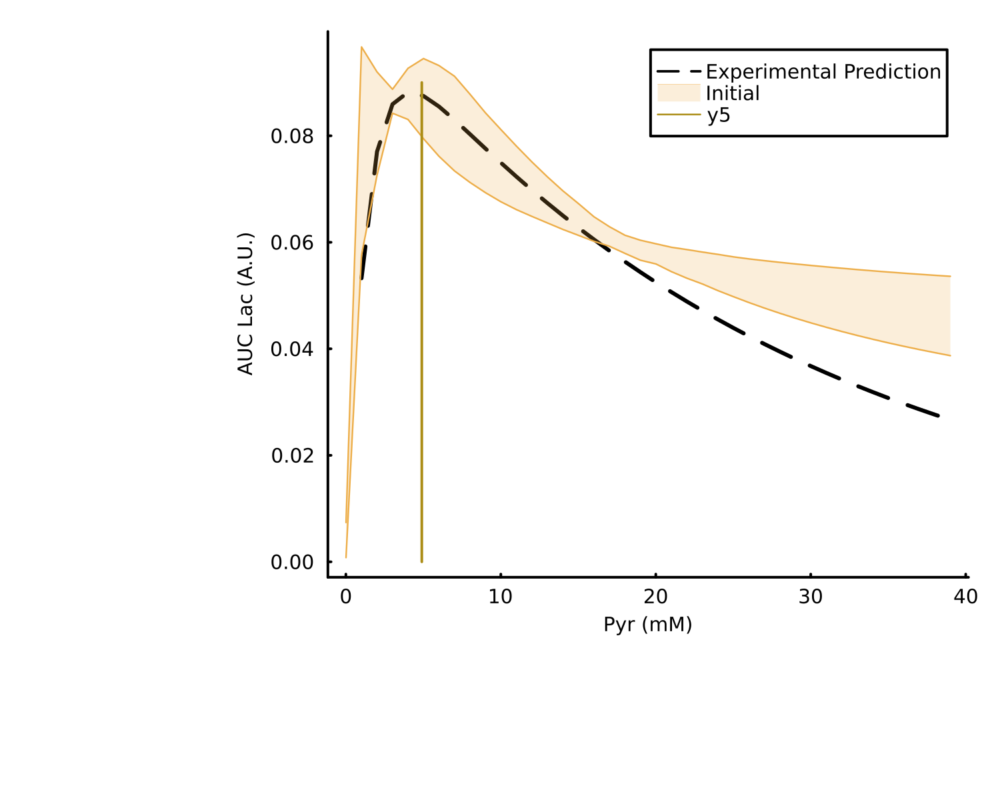

In [56]:
ccpal = ["#edae49ff","#00798cff","#d1495bff"];

pp = [71.52456846326336, 149.72936537382074, 0.035641505051707635, -155.7168946583787, 0.7919342251656567]
ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))
oblcrl = ss(PyrCons4, pp)./10^5;

po2 = plot(PyrCons4[oblcrl.>0], oblcrl[oblcrl.>0], label = "Experimental Prediction", markersize=1, markerstrokewidth=0.2, 
linewidth=1.5, size = (1500,1200), xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), thickness_scaling = 4, legendfontsize=5,
colour = "black", linestyle = :dash, grid = false)


# # -------------------------------------------------------------------------------------
# RANDOM
plot!(PyrCons4, lacSumQuant1[1,:]./10^5, label = "", color = ccpal[1],
  xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, markersize=1, markerstrokewidth=0.2, 
  linewidth=0.6, size = (1500,1200), xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), thickness_scaling = 4, legendfontsize=5)
plot!(PyrCons4, lacSumQuant1[2,:]./10^5, label = "", color = ccpal[1], linewidth=0.6)
plot!(PyrCons4, lacSumQuant1[2,:]./10^5, fillrange=convert.(Float64, lacSumQuant1[1,:]./10^5), color=ccpal[1], fillalpha=0.2, linewidth = 0, label = "Initial")

plot!([4.9,4.9],[0, 0.09])

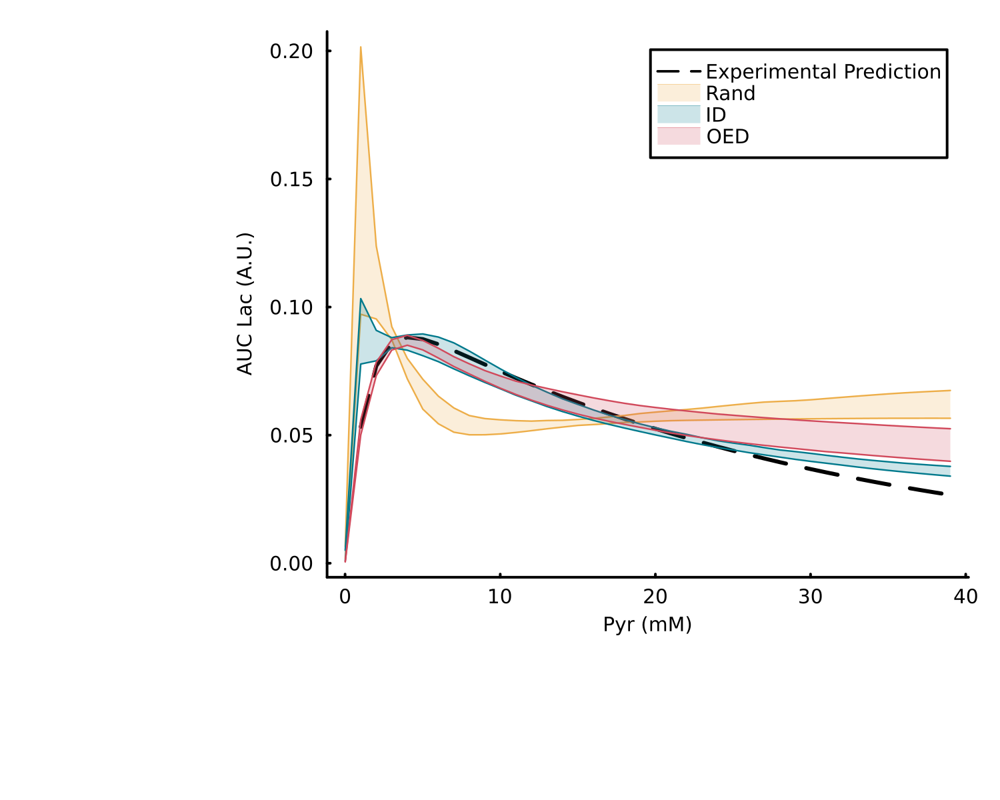

In [27]:
ccpal = ["#edae49ff","#00798cff","#d1495bff"];

pp = [71.52456846326336, 149.72936537382074, 0.035641505051707635, -155.7168946583787, 0.7919342251656567]
ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))
oblcrl = ss(PyrCons4, pp)./10^5;

po2 = plot(PyrCons4[oblcrl.>0], oblcrl[oblcrl.>0], label = "Experimental Prediction", markersize=1, markerstrokewidth=0.2, 
linewidth=1.5, size = (1500,1200), xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), thickness_scaling = 4, legendfontsize=5,
colour = "black", linestyle = :dash, grid = false)


# # -------------------------------------------------------------------------------------
# RANDOM
plot!(PyrCons4, lacSumQuantR[1,:]./10^5, label = "", color = ccpal[1],
  xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, markersize=1, markerstrokewidth=0.2, 
  linewidth=0.6, size = (1500,1200), xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), thickness_scaling = 4, legendfontsize=5)
plot!(PyrCons4, lacSumQuantR[2,:]./10^5, label = "", color = ccpal[1], linewidth=0.6)
plot!(PyrCons4, lacSumQuantR[2,:]./10^5, fillrange=convert.(Float64, lacSumQuantR[1,:]./10^5), color=ccpal[1], fillalpha=0.2, linewidth = 0, label = "Rand")


# # -------------------------------------------------------------------------------------
# Intuition Driven
plot!(PyrCons4, lacSumQuantI[1,:]./10^5, label = "", color = ccpal[2],
  xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, markersize=1, markerstrokewidth=0.2, 
  linewidth=0.6, size = (1500,1200), xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), thickness_scaling = 4, legendfontsize=5)
plot!(PyrCons4, lacSumQuantI[2,:]./10^5, label = "", color = ccpal[2], linewidth=0.6)
plot!(PyrCons4, lacSumQuantI[2,:]./10^5, fillrange=convert.(Float64, lacSumQuantI[1,:]./10^5), color=ccpal[2], fillalpha=0.2, linewidth = 0, label = "ID")



# # -------------------------------------------------------------------------------------
# OED
plot!(PyrCons4, lacSumQuantO[1,:]./10^5, label = "", color = ccpal[3],
  xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, markersize=1, markerstrokewidth=0.2, 
  linewidth=0.6, size = (1500,1200), xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), thickness_scaling = 4, legendfontsize=5)
plot!(PyrCons4, lacSumQuantO[2,:]./10^5, label = "", color = ccpal[3], linewidth=0.6)
plot!(PyrCons4, lacSumQuantO[2,:]./10^5, fillrange=convert.(Float64, lacSumQuantO[1,:]./10^5), color=ccpal[3], fillalpha=0.2, linewidth = 0, label = "OED")



# savefig(po2,"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure3Stuff\\AllModelPredictions.svg")

display(po2)

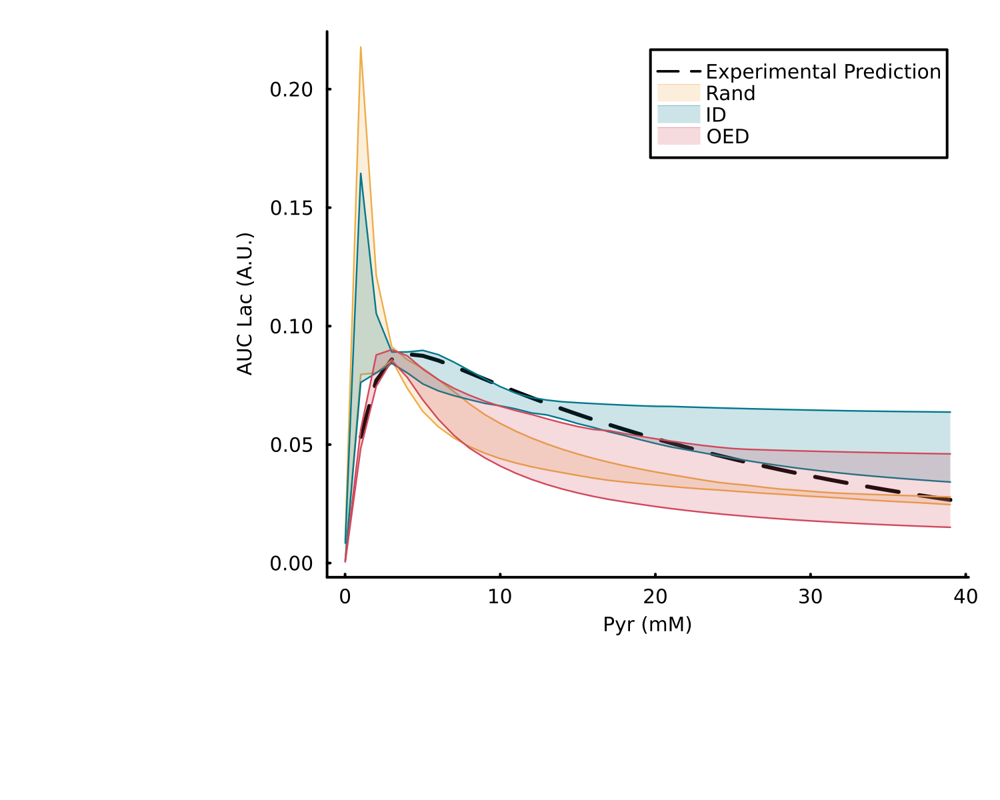

In [19]:
ccpal = ["#edae49ff","#00798cff","#d1495bff"];

pp = [71.52456846326336, 149.72936537382074, 0.035641505051707635, -155.7168946583787, 0.7919342251656567]
ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))
oblcrl = ss(PyrCons4, pp)./10^5;

po2 = plot(PyrCons4[oblcrl.>0], oblcrl[oblcrl.>0], label = "Experimental Prediction", markersize=1, markerstrokewidth=0.2, 
linewidth=1.5, size = (1500,1200), xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), thickness_scaling = 4, legendfontsize=5,
colour = "black", linestyle = :dash, grid = false)


# # -------------------------------------------------------------------------------------
# RANDOM
plot!(PyrCons4, lacSumQuantR[1,:]./10^5, label = "", color = ccpal[1],
  xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, markersize=1, markerstrokewidth=0.2, 
  linewidth=0.6, size = (1500,1200), xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), thickness_scaling = 4, legendfontsize=5)
plot!(PyrCons4, lacSumQuantR[2,:]./10^5, label = "", color = ccpal[1], linewidth=0.6)
plot!(PyrCons4, lacSumQuantR[2,:]./10^5, fillrange=convert.(Float64, lacSumQuantR[1,:]./10^5), color=ccpal[1], fillalpha=0.2, linewidth = 0, label = "Rand")


# # -------------------------------------------------------------------------------------
# Intuition Driven
plot!(PyrCons4, lacSumQuantI[1,:]./10^5, label = "", color = ccpal[2],
  xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, markersize=1, markerstrokewidth=0.2, 
  linewidth=0.6, size = (1500,1200), xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), thickness_scaling = 4, legendfontsize=5)
plot!(PyrCons4, lacSumQuantI[2,:]./10^5, label = "", color = ccpal[2], linewidth=0.6)
plot!(PyrCons4, lacSumQuantI[2,:]./10^5, fillrange=convert.(Float64, lacSumQuantI[1,:]./10^5), color=ccpal[2], fillalpha=0.2, linewidth = 0, label = "ID")



# # -------------------------------------------------------------------------------------
# OED
plot!(PyrCons4, lacSumQuantO[1,:]./10^5, label = "", color = ccpal[3],
  xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, markersize=1, markerstrokewidth=0.2, 
  linewidth=0.6, size = (1500,1200), xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), thickness_scaling = 4, legendfontsize=5)
plot!(PyrCons4, lacSumQuantO[2,:]./10^5, label = "", color = ccpal[3], linewidth=0.6)
plot!(PyrCons4, lacSumQuantO[2,:]./10^5, fillrange=convert.(Float64, lacSumQuantO[1,:]./10^5), color=ccpal[3], fillalpha=0.2, linewidth = 0, label = "OED")



# savefig(po2,"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure3Stuff\\AllModelPredictions.svg")

display(po2)

4.9

# Entropy Noise Analysis

In [48]:
mes = [0.00475, 0.01375, 0.045, 0.55, 0.95, 0.95, 0.95, 0.0085, 0.95, 0.002, 650, 16000, 550];
sts = [0.001, 0.005, 0.0025, 0.025, 0.02, 0.02, 0.02, 0.00025, 0.03, 0.00015, 260, 6400, 275];

HPriorN = entropy(MvNormal(mes, Diagonal(ones(13)).*sts));
HPriorN

1.3029696985123955

In [16]:
postsN = Array{Any}(undef, 10)
for i in 1:10
    tmp = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\Results\\PosteriorNoiseInformContSim_NIC_"*string(i)*"_Try1.csv", DataFrame))
    postsN[i] = hcat(tmp[:,3:12], tmp[:,14:end])
end

In [17]:
grid_searchM1FR1 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), postsN[1])

grid_searchM1FbR1 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR1.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR1.best_estimator_.n*4:grid_searchM1FR1.best_estimator_.n*4)), verbose=0), postsN[1])

K-means converged with 8 iterations (objv = 2.224961636319662e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 15 iterations (objv = 2.1466717945743057e10)
K-means converged with 7 iterations (objv = 2.1687825815202583e10)


┌ Info: K-means with 2000 data points using 8 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 15 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 17 iterations (objv = 1.6890729931686682e10)
K-means converged with 22 iterations (objv = 1.5625077568506695e10)


...

K-means converged with 35 iterations (objv = 1.4680007720719044e9)
K-means converged with 43 iterations (objv = 1.5239537748453515e9)


┌ Info: K-means with 5333 data points using 35 iterations
│ 23.8 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 16 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 43 iterations
│ 23.8 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 41 iterations (objv = 2.2524606243581715e9)


┌ Info: Initializing GMM, 16 Gaussians diag covariance 13 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 8000 data points using 41 iterations
│ 35.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 1.9091702218601994
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [18]:
grid_searchM1FR2 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), postsN[2])

grid_searchM1FbR2 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR2.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR2.best_estimator_.n*4:grid_searchM1FR2.best_estimator_.n*4)), verbose=0), postsN[2])

K-means converged with 18 iterations (objv = 2.3737229748106667e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 18 iterations (objv = 2.373487489862314e10)
K-means converged with 11 iterations (objv = 2.4155204971038696e10)


┌ Info: K-means with 2000 data points using 18 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 18 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 11 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 13 dimensions using 5333 dat

K-means converged with 21 iterations (objv = 1.906620407419168e10)
K-means converged with 7 iterations (objv = 1.9546994976657806e10)


...

K-means terminated without convergence after 50 iterations (objv = 1.2343401252930508e9)


┌ Warning: Too low occupancy count 0.0 for Gausian 18
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 13 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 18
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 13 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Info: Initializing GMM, 20 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 50 iterations
│ 19.1 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means terminated without convergence after 50 iterations (objv = 2.000360815110352e9)


┌ Info: Initializing GMM, 20 Gaussians diag covariance 13 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 8000 data points using 50 iterations
│ 28.6 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 1.8232854648469539
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [20]:
grid_searchM1FR3 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), postsN[3])

grid_searchM1FbR3 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR3.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR3.best_estimator_.n*4:grid_searchM1FR3.best_estimator_.n*4)), verbose=0), postsN[3])

K-means converged with 10 iterations (objv = 2.4360701577309177e10)
K-means converged with 15 iterations (objv = 2.36242964718795e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 10 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 15 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 10 iterations (objv = 2.566343240401574e10)
K-means converged with 18 iterations (objv = 1.8895299284136974e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 10 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 3000 data points using 18 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 23 iterations (objv = 1.82876318421576e10)
K-means converged with 19 iterations (objv = 1.8717111379940407e10)


...

K-means terminated without convergence after 50 iterations (objv = 1.3117371235179267e9)


┌ Info: Initializing GMM, 20 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means terminated without convergence after 50 iterations (objv = 1.8833849257762551e9)


┌ Info: K-means with 5334 data points using 50 iterations
│ 19.1 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 20 Gaussians diag covariance 13 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 8000 data points using 50 iterations
│ 28.6 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 1.7673552565510633
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [21]:
grid_searchM1FR4 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), postsN[4])

grid_searchM1FbR4 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR4.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR4.best_estimator_.n*4:grid_searchM1FR4.best_estimator_.n*4)), verbose=0), postsN[4])

K-means converged with 9 iterations (objv = 2.687653034637404e10)
K-means converged with 12 iterations (objv = 2.564774107077301e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 9 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 12 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 15 iterations (objv = 2.5562314359565056e10)
K-means converged with 13 iterations (objv = 2.0686780734735683e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 15 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 22 iterations (objv = 2.021331173656907e10)
K-means converged with 21 iterations (objv = 2.022070083544447e10)


...

K-means terminated without convergence after 50 iterations (objv = 3.3259554839822154e9)


┌ Info: K-means with 5333 data points using 50 iterations
│ 31.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 12 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means terminated without convergence after 50 iterations (objv = 4.824807901892722e9)


┌ Info: K-means with 5334 data points using 50 iterations
│ 31.8 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 12 Gaussians diag covariance 13 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 8000 data points using 50 iterations
│ 47.6 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 1.6801753124242562
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [22]:
grid_searchM1FR5 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), postsN[5])

grid_searchM1FbR5 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR5.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR5.best_estimator_.n*4:grid_searchM1FR5.best_estimator_.n*4)), verbose=0), postsN[5])

K-means converged with 15 iterations (objv = 2.5867351033723244e10)
K-means converged with 12 iterations (objv = 2.5467039966106102e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 15 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 15 iterations (objv = 2.5635980626264668e10)
K-means converged with 23 iterations (objv = 1.960217357367691e10)


┌ Info: K-means with 2000 data points using 12 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 15 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 14 iterations (objv = 1.946999232619095e10)
K-means converged with 32 iterations (objv = 2.0219133319952503e10)


...

K-means converged with 30 iterations (objv = 1.834844657366716e9)


┌ Info: Initializing GMM, 16 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 30 iterations
│ 23.8 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 16 Gaussians diag covariance 13 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means terminated without convergence after 50 iterations (objv = 2.8593684854037857e9)


┌ Info: K-means with 8000 data points using 50 iterations
│ 35.7 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 1.7028741593272212
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [28]:
grid_searchM1FR6 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), postsN[6])

grid_searchM1FbR6 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR6.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR6.best_estimator_.n*4:grid_searchM1FR6.best_estimator_.n*4)), verbose=0), postsN[6])

K-means converged with 16 iterations (objv = 2.4829870923224113e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 16 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 11 iterations (objv = 2.351763640648542e10)
K-means converged with 13 iterations (objv = 2.6139408647905006e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 11 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 40 iterations (objv = 2.1106843612687122e10)


...

K-means converged with 42 iterations (objv = 1.6585454895292714e9)


┌ Warning: 13 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Info: Initializing GMM, 20 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 42 iterations
│ 19.1 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Warning: Too low occupancy count 0.0 for Gausian 17
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 13 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 17
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 13 pathological elements normalized
└ @ GaussianM

K-means converged with 49 iterations (objv = 2.424514942659145e9)


┌ Info: K-means with 8000 data points using 49 iterations
│ 28.6 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 1.5623190486263603
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [31]:
grid_searchM1FR7 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), postsN[7])

grid_searchM1FbR7 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR7.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR7.best_estimator_.n*4:grid_searchM1FR7.best_estimator_.n*4)), verbose=0), postsN[7])

GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 1.624932145468421
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [25]:
grid_searchM1FR8 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), postsN[8])

grid_searchM1FbR8 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR8.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR8.best_estimator_.n*4:grid_searchM1FR8.best_estimator_.n*4)), verbose=0), postsN[8])

K-means converged with 12 iterations (objv = 2.922324572589566e10)
K-means converged with 16 iterations (objv = 2.8853634011124565e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 12 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 16 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 13 iterations (objv = 2.857211756501433e10)
K-means converged with 34 iterations (objv = 2.292689539385853e10)

┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 13 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 3 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79



K-means converged with 32 iterations (objv = 2.281970731840806e10)
K-means converged with 30 iterations (objv = 2.369197750444853e10)


...

K-means converged with 48 iterations (objv = 9.710290189818227e8)


┌ Info: Initializing GMM, 28 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 48 iterations
│ 13.6 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Warning: Too low occupancy count 0.0 for Gausian 24
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 13 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 24
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:266
┌ Warning: 13 pathological elements normalized
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:69
┌ Warning: Too low occupancy count 0.0 for Gausian 24
└ @ Ga

K-means terminated without convergence after 50 iterations (objv = 1.4482700605050535e9)


┌ Info: K-means with 8000 data points using 50 iterations
│ 20.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 1.5866326488064697
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [26]:
grid_searchM1FR9 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), postsN[9])

grid_searchM1FbR9 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR9.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR9.best_estimator_.n*4:grid_searchM1FR9.best_estimator_.n*4)), verbose=0), postsN[9])

K-means converged with 11 iterations (objv = 2.6874997819161636e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 11 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 3 iterations (objv = 2.5539999357499138e10)
K-means converged with 14 iterations (objv = 2.63666686821195e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 3 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 14 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 19 iterations (objv = 2.1376193320026367e10)
K-means converged with 21 iterations (objv = 2.0330698786782383e10)


...

K-means converged with 46 iterations (objv = 1.4578363052081265e9)


┌ Info: Initializing GMM, 20 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 46 iterations
│ 19.1 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 20 Gaussians diag covariance 13 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means terminated without convergence after 50 iterations (objv = 2.192397146367507e9)


┌ Info: K-means with 8000 data points using 50 iterations
│ 28.6 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 1.5862570036465211
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [27]:
grid_searchM1FR10 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=10, kind=:full), 
        Dict(:n_components=>collect(1:20)), verbose=0), postsN[10])

grid_searchM1FbR10 = ScikitLearnBase.fit!(GridSearchCV(GMM(n_components=grid_searchM1FR10.best_estimator_.n*4, kind=:full), 
        Dict(:n_components=>collect(grid_searchM1FR10.best_estimator_.n*4:grid_searchM1FR10.best_estimator_.n*4)), verbose=0), postsN[10])

K-means converged with 19 iterations (objv = 2.9778459764733826e10)


┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79


K-means converged with 10 iterations (objv = 2.8707352863118786e10)
K-means converged with 16 iterations (objv = 3.009925012003875e10)


┌ Info: K-means with 2000 data points using 19 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5333 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 10 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 2 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 2000 data points using 16 iterations
│ 71.4 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means converged with 22 iterations (objv = 2.254205480531427e10)
K-means converged with 33 iterations (objv = 2.0851683792055748e10)


...


K-means converged with 33 iterations (objv = 1.5840972594593716e9)


┌ Info: K-means with 5333 data points using 50 iterations
│ 19.0 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141
┌ Info: Initializing GMM, 20 Gaussians diag covariance 13 dimensions using 5334 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 5334 data points using 33 iterations
│ 19.1 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


K-means terminated without convergence after 50 iterations (objv = 2.6634820992289968e9)


┌ Info: Initializing GMM, 20 Gaussians diag covariance 13 dimensions using 8000 data points
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:79
┌ Info: K-means with 8000 data points using 50 iterations
│ 28.6 data points per parameter
└ @ GaussianMixtures C:\Users\dgomez\.julia\packages\GaussianMixtures\yHlNS\src\train.jl:141


GridSearchCV
  estimator: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}
  param_grid: Dict{Symbol, Vector{Int64}}
  scoring: Nothing nothing
  loss_func: Nothing nothing
  score_func: Nothing nothing
  fit_params: Dict{Any, Any}
  n_jobs: Int64 1
  iid: Bool true
  refit: Bool true
  cv: Nothing nothing
  verbose: Int64 0
  error_score: String "raise"
  scorer_: score (function of type typeof(ScikitLearnBase.score))
  best_params_: Dict{Symbol, Any}
  best_score_: Float64 1.5946896014747678
  grid_scores_: Array{ScikitLearn.Skcore.CVScoreTuple}((1,))
  best_estimator_: GMM{Float64, Vector{UpperTriangular{Float64, Matrix{Float64}}}}


In [32]:
gridsInitN = [grid_searchM1FbR1, grid_searchM1FbR2, grid_searchM1FbR3, grid_searchM1FbR4, grid_searchM1FbR5, grid_searchM1FbR6, grid_searchM1FbR7, grid_searchM1FbR8, grid_searchM1FbR9, grid_searchM1FbR10];

In [41]:
# First dimension number of experiments, second dimension type of experiments.
compsN = Array{Any,2}(undef,10, 1);
weisN = Array{Any,2}(undef, 10, 1);
meaasN = Array{Any,2}(undef,10, 1);
covasN = Array{Any,2}(undef,10, 1);

for i in 1:10 #number of experiments
    # Get and store best results
    compsN[i,1] = length(gridsInitN[i].best_estimator_.w); # Number of components
    weisN[i,1] = gridsInitN[i].best_estimator_.w; # Weights for each component
    meaasN[i,1] = gridsInitN[i].best_estimator_.μ; # Means for each component
    covasN[i,1] = [inv(Matrix(gridsInitN[i].best_estimator_.Σ[j]))*inv(Matrix(gridsInitN[i].best_estimator_.Σ[j])') 
        for j in 1:length(gridsInitN[i].best_estimator_.Σ)]; # Covariance Matrix for each component
end


In [42]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\ResultsPostAnal\\GMMPosters_NoiseAnalysis.jld", "compsN", compsN, "weisN", weisN, "meaasN", meaasN, "covasN", covasN)

In [ ]:
compsN = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\ResultsPostAnal\\GMMPosters_NoiseAnalysis.jld")["compsN"];
weisN = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\ResultsPostAnal\\GMMPosters_NoiseAnalysis.jld")["weisN"];
meaasN = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\ResultsPostAnal\\GMMPosters_NoiseAnalysis.jld")["meaasN"];
covasN = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\ResultsPostAnal\\GMMPosters_NoiseAnalysis.jld")["covasN"];

In [43]:
H_U_PostN = Array{Any,2}(undef,10,1);
H_L_PostN = Array{Any,2}(undef,10,1);
H_PostN = Array{Any,2}(undef,10,1);

for j in 1:10# number of experiments
    [H_U_PostN[j,i] = H_Upper(weisN[j,i], covasN[j,i]) for i in 1:1];
    [H_L_PostN[j,i] = H_Lower(weisN[j,i], covasN[j,i], meaasN[j,i]) for i in 1:1];
    [H_PostN[j,i] = H_est(compsN[j,i], weisN[j,i], meaasN[j,i], covasN[j,i]) for i in 1:1];
end

In [49]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\Results\\EntroPosters.jld", "H_U_PostN", H_U_PostN, "H_L_PostN", H_L_PostN, "H_PostN", H_PostN, "HPriorN", HPriorN)

In [ ]:
H_U_Post = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\Results\\EntroPosters.jld")["H_U_Post"];
H_L_Post = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\Results\\EntroPosters.jld")["H_L_Post"];
H_Post = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\Results\\EntroPosters.jld")["H_Post"];

In [47]:
display(string("              |     H Lower Bound      |            H            |      H Upper Bound      |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 1   |      ",round(H_L_PostN[1,1], digits = 8),"      |       ",round(H_PostN[1,1], digits = 9),"        |       ",round(H_U_PostN[1,1], digits = 9),"       |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 2   |      ",round(H_L_PostN[2,1], digits = 8),"      |       ",round(H_PostN[2,1], digits = 6),"        |       ",round(H_U_PostN[2,1], digits = 8),"        |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 3   |      ",round(H_L_PostN[3,1], digits = 8),"      |       ",round(H_PostN[3,1], digits = 6),"         |       ",round(H_U_PostN[3,1], digits = 8),"       |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 4   |      ",round(H_L_PostN[4,1], digits = 8),"      |       ",round(H_PostN[4,1], digits = 9),"        |       ",round(H_U_PostN[4,1], digits = 9),"       |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 5   |      ",round(H_L_PostN[5,1], digits = 8),"      |       ",round(H_PostN[5,1], digits = 6),"        |       ",round(H_U_PostN[5,1], digits = 8),"        |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 6   |      ",round(H_L_PostN[6,1], digits = 8),"      |       ",round(H_PostN[6,1], digits = 6),"         |       ",round(H_U_PostN[6,1], digits = 8),"       |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 7   |      ",round(H_L_PostN[7,1], digits = 8),"      |       ",round(H_PostN[7,1], digits = 9),"        |       ",round(H_U_PostN[7,1], digits = 9),"       |"))
display("------------------------------------------------------------------------------------------")
display(string("|    Rand 8   |      ",round(H_L_PostN[8,1], digits = 8),"      |       ",round(H_PostN[8,1], digits = 6),"        |       ",round(H_U_PostN[8,1], digits = 8),"        |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 9   |      ",round(H_L_PostN[9,1], digits = 8),"      |       ",round(H_PostN[9,1], digits = 6),"         |       ",round(H_U_PostN[9,1], digits = 8),"       |"))
display("--------------------------------------------------------------------------------------------")
display(string("|    Rand 10  |      ",round(H_L_PostN[10,1], digits = 8),"      |       ",round(H_PostN[10,1], digits = 6),"         |       ",round(H_U_PostN[10,1], digits = 8),"       |"))
display("--------------------------------------------------------------------------------------------")


"              |     H Lower Bound      |            H            |      H Upper Bound      |"

"--------------------------------------------------------------------------------------------"

"|    Rand 1   |      -37.26576959      |       -35.182474351        |       -24.860235625       |"

"--------------------------------------------------------------------------------------------"

"|    Rand 2   |      -36.31424873      |       -34.20905        |       -23.86905167        |"

...

"--------------------------------------------------------------------------------------------"

"|    Rand 9   |      -32.99191549      |       -30.801644         |       -20.55326116       |"

"--------------------------------------------------------------------------------------------"

"|    Rand 10  |      -33.29829582      |       -31.242719         |       -20.89419851       |"

"--------------------------------------------------------------------------------------------"